Fase 1: Transformación y Limpieza de Datos 

In [19]:
#Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore", category=UserWarning)


In [20]:
#Cargamos Archivo CSV:
df_banco = pd.read_csv('bank-additional.csv') 
df_banco.head()



,Unnamed: 0,age,job,marital,education,default,housing,loan,contact,duration,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_
0,0,NaN,housemaid,MARRIED,basic.4y,0.0,0.0,0.0,telephone,261,...,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,57.0,services,MARRIED,high.school,NaN,0.0,0.0,telephone,149,...,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097
2,2,37.0,services,MARRIED,high.school,0.0,1.0,0.0,telephone,226,...,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,40.0,admin.,MARRIED,basic.6y,0.0,0.0,0.0,telephone,151,...,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,56.0,services,MARRIED,high.school,0.0,0.0,1.0,telephone,307,...,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


In [21]:
df_banco.describe()
df_banco.info()
df_banco.shape

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      43000 non-null  int64  
 1   age             37880 non-null  float64
 2   job             42655 non-null  str    
 3   marital         42915 non-null  str    
 4   education       41193 non-null  str    
 5   default         34019 non-null  float64
 6   housing         41974 non-null  float64
 7   loan            41974 non-null  float64
 8   contact         43000 non-null  str    
 9   duration        43000 non-null  int64  
 10  campaign        43000 non-null  int64  
 11  pdays           43000 non-null  int64  
 12  previous        43000 non-null  int64  
 13  poutcome        43000 non-null  str    
 14  emp.var.rate    43000 non-null  float64
 15  cons.price.idx  42529 non-null  str    
 16  cons.conf.idx   43000 non-null  str    
 17  euribor3m       33744 non-null  str    
 1

(43000, 24)

In [22]:
#Cargamos Archivo Excel
# 1. Abrir el archivo como contenedor Excel para inspeccionar su estructura
excel_file = pd.ExcelFile("customer-details.xlsx")

# 2. Obtener la lista con los nombres de todas las hojas
hojas = excel_file.sheet_names
print("Hojas encontradas:", hojas)

# 3. Obtener el número total de hojas usando len()
num_hojas = len(hojas)
print(f"El archivo tiene un total de {num_hojas} hojas.")

# 4. Cargar una de las hojas en un DataFrame para ver sus datos
df_clientes = pd.read_excel(excel_file, sheet_name="2012")
df_clientes.head()

Hojas encontradas: ['2012', '2013', '2014']
El archivo tiene un total de 3 hojas.


,Unnamed: 0,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID
0,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097
2,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,121393,1,2,2012-12-21,29,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,63164,1,2,2012-06-20,20,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


In [23]:
# Leer y concatenar las hojas de los años 2012, 2013 y 2014
# 1. Tenemos abierto el archivo Excel como objeto contenedor
# 2. Inicializar una lista vacía para guardar los DataFrames de cada hoja
lista_dfs = []

# 3. Recorrer las hojas usando el objeto 'excel_file'
for sheet in excel_file.sheet_names:
  df_sheet = pd.read_excel(excel_file, sheet_name=sheet)
  df_sheet["anio_registro_hoja"] = sheet  # Añadimos metadato de origen
  lista_dfs.append(df_sheet)

# 4. Concatenar todos los DataFrames de la lista en el DataFrame final
df_clientes = pd.concat(lista_dfs, ignore_index=True)

# 5. Comprobar el resultado
print("\n--- CLIENTES DATASET CONCATENADO ---")
df_clientes.shape
df_clientes.info()
df_clientes.head(3)


--- CLIENTES DATASET CONCATENADO ---
<class 'pandas.DataFrame'>
RangeIndex: 43170 entries, 0 to 43169
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Unnamed: 0          43170 non-null  int64         
 1   Income              43170 non-null  int64         
 2   Kidhome             43170 non-null  int64         
 3   Teenhome            43170 non-null  int64         
 4   Dt_Customer         43170 non-null  datetime64[us]
 5   NumWebVisitsMonth   43170 non-null  int64         
 6   ID                  43170 non-null  str           
 7   anio_registro_hoja  43170 non-null  str           
dtypes: datetime64[us](1), int64(5), str(2)
memory usage: 2.6 MB


,Unnamed: 0,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID,anio_registro_hoja
0,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079,2012
1,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097,2012
2,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b,2012


In [24]:
#Unimos los dataframes de clientes y banco en uno solo, para tener toda la información en un solo dataset a traves de la columna ID
tabla_clientes_datos_banco=pd.merge(df_clientes, df_banco, how='inner', left_on='ID', right_on='id_')
tabla_clientes_datos_banco.shape
tabla_clientes_datos_banco.info()
tabla_clientes_datos_banco.head(3)
#Mas adelante eliminaremo Unnamed: 0_x, Unnamed: 0_y y una de las dos columnas de ID repetidas

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Unnamed: 0_x        43000 non-null  int64         
 1   Income              43000 non-null  int64         
 2   Kidhome             43000 non-null  int64         
 3   Teenhome            43000 non-null  int64         
 4   Dt_Customer         43000 non-null  datetime64[us]
 5   NumWebVisitsMonth   43000 non-null  int64         
 6   ID                  43000 non-null  str           
 7   anio_registro_hoja  43000 non-null  str           
 8   Unnamed: 0_y        43000 non-null  int64         
 9   age                 37880 non-null  float64       
 10  job                 42655 non-null  str           
 11  marital             42915 non-null  str           
 12  education           41193 non-null  str           
 13  default             34019 non-null  float64       
 14  h

,Unnamed: 0_x,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID,anio_registro_hoja,Unnamed: 0_y,age,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_
0,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079,2012,0,NaN,...,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097,2012,1,57.0,...,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097
2,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b,2012,2,37.0,...,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b


In [25]:
#Eliminar columnas innecesarias / duplicadas tras el merge
columnas_a_eliminar = ["Unnamed: 0_x", "Unnamed: 0_y", "id_"]
df_clientes_datos_banco_limpio = tabla_clientes_datos_banco.drop(columns=columnas_a_eliminar, errors="ignore")
df_clientes_datos_banco_limpio.head()

,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID,anio_registro_hoja,age,job,marital,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude
0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079,2012,NaN,housemaid,MARRIED,...,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233
1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097,2012,57.0,services,MARRIED,...,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923
2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b,2012,37.0,services,MARRIED,...,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847
3,121393,1,2,2012-12-21,29,9991fafb-4447-451a-8be2-b0df6098d13e,2012,40.0,admin.,MARRIED,...,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308
4,63164,1,2,2012-06-20,20,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,2012,56.0,services,MARRIED,...,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463


In [26]:
# 1. Revisar valores nulos ordenados de mayor a menor
print("--- VALORES NULOS POR COLUMNA ---")
nulos = df_clientes_datos_banco_limpio.isna().sum()
print(nulos[nulos > 0].sort_values(ascending=False))

# 2. Revisar tipos de datos actuales
print("\n--- TIPOS DE DATOS ---")
print(df_clientes_datos_banco_limpio.dtypes)

--- VALORES NULOS POR COLUMNA ---
euribor3m         9256
default           8981
age               5120
education         1807
housing           1026
loan              1026
cons.price.idx     471
job                345
date               248
marital             85
dtype: int64

--- TIPOS DE DATOS ---
Income                         int64
Kidhome                        int64
Teenhome                       int64
Dt_Customer           datetime64[us]
NumWebVisitsMonth              int64
ID                               str
anio_registro_hoja               str
age                          float64
job                              str
marital                          str
education                        str
default                      float64
housing                      float64
loan                         float64
contact                          str
duration                       int64
campaign                       int64
pdays                          int64
previous                       in

In [27]:
# Extraer el nombre del trabajo, estado civil y ultimo resultado ejercicio anterior en minúsculas de las fechas no nulas para ver si hay inconsistencias en los datos
columnas_cat = ["job", "marital", "poutcome"]

for col in columnas_cat:
  serie_col = (
      df_clientes_datos_banco_limpio[col]
      .dropna()
      .astype(str)
      .str.strip()
      .str.lower()
  )

  # 1. Ver todas las opciones únicas ordenadas
  valores_unicos = sorted(serie_col.unique())
  print(f"=== COLUMNA: '{col}' ===")
  print(f"Total de valores únicos detectados: {len(valores_unicos)}")
  print("Opciones únicas:", valores_unicos)

  # 2. Ver la frecuencia de cada valor
  print("\nFrecuencia por valor:")
  print(serie_col.value_counts())
  print("-" * 50)

=== COLUMNA: 'job' ===
Total de valores únicos detectados: 11
Opciones únicas: ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed']

Frecuencia por valor:
job
admin.           10873
blue-collar       9654
technician        7026
services          4162
management        3050
retired           1790
entrepreneur      1522
self-employed     1489
housemaid         1123
unemployed        1063
student            903
Name: count, dtype: int64
--------------------------------------------------
=== COLUMNA: 'marital' ===
Total de valores únicos detectados: 3
Opciones únicas: ['divorced', 'married', 'single']

Frecuencia por valor:
marital
married     25999
single      12105
divorced     4811
Name: count, dtype: int64
--------------------------------------------------
=== COLUMNA: 'poutcome' ===
Total de valores únicos detectados: 3
Opciones únicas: ['failure', 'nonexistent', 'success']

Frecuencia por v

In [28]:
#Verificar variantes de fechas en la columna 'date'
# Extraer la parte central (entre guiones) de las fechas no nulas de 'date'
meses_detectados = (
    df_clientes_datos_banco_limpio["date"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .str.extract(r"^\d{1,2}-([a-z]+)-\d{4}$", expand=False)
    .value_counts(dropna=False)
    )

print("--- VALORES DE MES DETECTADOS EN 'date' ---")
print(meses_detectados)

--- VALORES DE MES DETECTADOS EN 'date' ---
date
noviembre     3603
octubre       3599
julio         3593
marzo         3589
abril         3582
febrero       3577
septiembre    3569
mayo          3547
junio         3538
agosto        3526
enero         3517
diciembre     3512
Name: count, dtype: int64


In [29]:
#Bloque de limpieza y formateo en Pandas
# Trabajamos sobre una copia para no perder el original
df_clientes_datos_banco_clean = df_clientes_datos_banco_limpio.copy()

# 1. Convertir columnas económicas con coma decimal a float
cols_numericas_coma = [
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]
for col in cols_numericas_coma:
  if col in df_clientes_datos_banco_clean.columns:
    df_clientes_datos_banco_clean[col] = pd.to_numeric(
        df_clientes_datos_banco_clean[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce",
    )

# 2. Igualar formato de fechas: mapear meses en español en 'date' y pasar a datetime
meses_es = {
    "enero": "01",
    "febrero": "02",
    "marzo": "03",
    "abril": "04",
    "mayo": "05",
    "junio": "06",
    "julio": "07",
    "agosto": "08",
    "septiembre": "09",
    "setiembre": "09",
    "octubre": "10",
    "noviembre": "11",
    "diciembre": "12",
}

#Si el valor está vacío o es nulo (NaN, None, etc.), devuelve pd.NaT (Not a Time, el equivalente a NaN para fechas) en lugar de intentar procesarlo o fallar.
def parchear_fecha_es(valor):
  if pd.isna(valor):
    return pd.NaT
  texto = str(valor).strip().lower()
  for mes, num in meses_es.items():
    if f"-{mes}-" in texto:
      texto = texto.replace(f"-{mes}-", f"-{num}-")
      break
  return pd.to_datetime(texto, format="%d-%m-%Y", errors="coerce")


df_clientes_datos_banco_clean["date"] = df_clientes_datos_banco_clean["date"].apply(parchear_fecha_es)
df_clientes_datos_banco_clean["Dt_Customer"] = pd.to_datetime(
    df_clientes_datos_banco_clean["Dt_Customer"], errors="coerce"
)

# 3. Normalizar columnas de texto (sin tocar ID) a MAYÚSCULAS y sin espacios sobrantes
cols_texto = ["job", "marital", "education", "contact", "poutcome", "y"]
for col in cols_texto:
  if col in df_clientes_datos_banco_clean.columns:
    df_clientes_datos_banco_clean[col] = df_clientes_datos_banco_clean[col].apply(
        lambda x: x.strip().upper() if isinstance(x, str) else x
    )

# 4. Revisar caracteres no alfanuméricos habituales en columnas de texto
for col in cols_texto:
  if col in df_clientes_datos_banco_clean.columns:
    unicos = df_clientes_datos_banco_clean[col].dropna().unique()
    print(f"{col}: {unicos}")

# 5. Tratamiento inicial de nulos
cols_cat_nulos = ["default", "education", "housing", "loan", "job", "marital"]
for col in cols_cat_nulos:
  if col in df_clientes_datos_banco_clean.columns:
    df_clientes_datos_banco_clean[col] = df_clientes_datos_banco_clean[col].fillna("SIN_DATO")

for col in ["age", "cons.price.idx", "euribor3m"]:
  if col in df_clientes_datos_banco_clean.columns:
    df_clientes_datos_banco_clean[col] = df_clientes_datos_banco_clean[col].fillna(df_clientes_datos_banco_clean[col].median())

print("\nNulos restantes tras la limpieza:")
print(df_clientes_datos_banco_clean.isna().sum()[df_clientes_datos_banco_clean.isna().sum() > 0])

job: <StringArray>
[    'HOUSEMAID',      'SERVICES',        'ADMIN.',   'BLUE-COLLAR',
    'TECHNICIAN',       'RETIRED',    'MANAGEMENT',    'UNEMPLOYED',
 'SELF-EMPLOYED',  'ENTREPRENEUR',       'STUDENT']
Length: 11, dtype: str
marital: <StringArray>
['MARRIED', 'SINGLE', 'DIVORCED']
Length: 3, dtype: str
education: <StringArray>
[           'BASIC.4Y',         'HIGH.SCHOOL',            'BASIC.6Y',
            'BASIC.9Y', 'PROFESSIONAL.COURSE',   'UNIVERSITY.DEGREE',
          'ILLITERATE']
Length: 7, dtype: str
contact: <StringArray>
['TELEPHONE', 'CELLULAR']
Length: 2, dtype: str
poutcome: <StringArray>
['NONEXISTENT', 'FAILURE', 'SUCCESS']
Length: 3, dtype: str
y: <StringArray>
['NO', 'YES']
Length: 2, dtype: str

Nulos restantes tras la limpieza:
date    248
dtype: int64


In [30]:
#Bloque de cierre de limpieza
# 1. Comprobar duplicados exactos
print(
    "Filas duplicadas exactas:",
    df_clientes_datos_banco_clean.duplicated().sum(),
)

# 2. Variable indicadora para pdays (999 = nunca contactado previamente en campaña)
df_clientes_datos_banco_clean["contactado_prev_pdays"] = (df_clientes_datos_banco_clean["pdays"] != 999).astype(int)

# 3. Variable numérica auxiliar para la variable objetivo 'y'
df_clientes_datos_banco_clean["y_num"] = df_clientes_datos_banco_clean["y"].map({"YES": 1, "NO": 0})

# 4. Extraer año y mes de contacto de 'date' (respetando NaT)
df_clientes_datos_banco_clean["anio_contacto"] = df_clientes_datos_banco_clean["date"].dt.year
df_clientes_datos_banco_clean["mes_contacto"] = df_clientes_datos_banco_clean["date"].dt.month

print(df_clientes_datos_banco_clean[["y", "y_num", "pdays", "contactado_prev_pdays", "date"]].head())

Filas duplicadas exactas: 0
    y  y_num  pdays  contactado_prev_pdays       date
0  NO      0    999                      0 2019-08-02
1  NO      0    999                      0 2016-09-14
2  NO      0    999                      0 2019-02-15
3  NO      0    999                      0 2015-11-29
4  NO      0    999                      0 2017-01-29


Fase 2: Análisis Descriptivo (EDA)

In [31]:
# 1. Distribución de la variable objetivo 'y'
print("--- 1. DISTRIBUCIÓN DE SUSCRIPCIÓN AL DEPÓSITO (y) ---")
conteo_y = df_clientes_datos_banco_clean["y"].value_counts()
porcentaje_y = df_clientes_datos_banco_clean["y"].value_counts(normalize=True) * 100
resumen_y = pd.DataFrame({"Conteo": conteo_y, "Porcentaje (%)": porcentaje_y.round(2)})
print(resumen_y)

# 2. Estadísticos descriptivos de variables numéricas clave
cols_numericas = [
    "age", "Income", "Kidhome", "Teenhome", "NumWebVisitsMonth",
    "duration", "campaign", "previous", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"
]
print("\n--- 2. ESTADÍSTICOS DESCRIPTIVOS (VARIABLES NUMÉRICAS) ---")
print(df_clientes_datos_banco_clean[cols_numericas].describe().round(2).T)

# 3. Función auxiliar para analizar tasa de conversión por categorías
def tasa_conversion_por(columna):
    tabla = (
        df_clientes_datos_banco_clean.groupby(columna)["y_num"]
        .agg(Total_Clientes="count", Suscripciones="sum", Tasa_Conversion_Pct="mean")
    )
    tabla["Tasa_Conversion_Pct"] = (tabla["Tasa_Conversion_Pct"] * 100).round(2)
    return tabla.sort_values(by="Tasa_Conversion_Pct", ascending=False)

print("\n--- 3A. TASA DE CONVERSIÓN POR OCUPACIÓN (job) ---")
print(tasa_conversion_por("job"))

print("\n--- 3B. TASA DE CONVERSIÓN POR RESULTADO CAMPAÑA PREVIA (poutcome) ---")
print(tasa_conversion_por("poutcome"))

print("\n--- 3C. TASA DE CONVERSIÓN POR CANAL DE CONTACTO (contact) ---")
print(tasa_conversion_por("contact"))

print("\n--- 3D. TASA DE CONVERSIÓN POR NIVEL EDUCATIVO (education) ---")
print(tasa_conversion_por("education"))

# 4. Comparativa de promedios según si suscribió o no (YES vs NO)
print("\n--- 4. COMPARATIVA DE MEDIAS SEGÚN RESULTADO (y) ---")
print(
    df_clientes_datos_banco_clean.groupby("y")[
        ["age", "Income", "duration", "campaign", "euribor3m", "NumWebVisitsMonth"]
    ].mean().round(2)
)

# 5. Mediana vs. media en variables clave según suscripción (y)
print("\n--- 5. MEDIANA VS. MEDIA SEGÚN RESULTADO (y) ---")
print(
    df_clientes_datos_banco_clean.groupby("y")[
        ["duration", "campaign", "euribor3m", "Income", "age"]
    ]
    .agg(["median", "mean"])
    .round(2)
)

# 6. Conversión por tramos de contactos en la campaña y contacto previo (pdays)
df_clientes_datos_banco_clean["tramo_campana"] = pd.cut(
    df_clientes_datos_banco_clean["campaign"],
    bins=[0, 1, 2, 3, 5, 100],
    labels=["1", "2", "3", "4-5", "6+"],
)

print("\n--- 6A. TASA DE CONVERSIÓN POR TRAMOS DE CONTACTOS (campaign) ---")
print(
    df_clientes_datos_banco_clean.groupby("tramo_campana", observed=False)["y_num"]
    .agg(Total_Clientes="count", Suscripciones="sum", Tasa_Conversion_Pct="mean")
    .assign(Tasa_Conversion_Pct=lambda x: (x["Tasa_Conversion_Pct"] * 100).round(2))
)

print("\n--- 6B. TASA DE CONVERSIÓN SEGÚN CONTACTO PREVIO (pdays != 999) ---")
print(
    df_clientes_datos_banco_clean.groupby("contactado_prev_pdays")["y_num"]
    .agg(Total_Clientes="count", Suscripciones="sum", Tasa_Conversion_Pct="mean")
    .assign(Tasa_Conversion_Pct=lambda x: (x["Tasa_Conversion_Pct"] * 100).round(2))
)

# 7. Correlaciones numéricas ordenadas respecto a y_num
correlaciones_y = (
    df_clientes_datos_banco_clean.select_dtypes(include=[np.number])
    .corr()["y_num"]
    .drop("y_num", errors="ignore")
    .sort_values(key=abs, ascending=False)
)
print("\n--- 7. CORRELACIONES CON y_num (ORDENADAS POR MAGNITUD) ---")
print(correlaciones_y.round(4))

--- 1. DISTRIBUCIÓN DE SUSCRIPCIÓN AL DEPÓSITO (y) ---
     Conteo  Porcentaje (%)
y                          
NO    38156           88.73
YES    4844           11.27

--- 2. ESTADÍSTICOS DESCRIPTIVOS (VARIABLES NUMÉRICAS) ---
                     count      mean       std      min       25%       50%  \
age                43000.0     39.74      9.82    17.00     33.00     38.00   
Income             43000.0  93241.20  50498.32  5841.00  49610.00  93050.50   
Kidhome            43000.0      1.00      0.82     0.00      0.00      1.00   
Teenhome           43000.0      1.00      0.82     0.00      0.00      1.00   
NumWebVisitsMonth  43000.0     16.59      9.24     1.00      9.00     17.00   
duration           43000.0    257.74    258.67     0.00    102.00    179.00   
campaign           43000.0      2.57      2.77     1.00      1.00      2.00   
previous           43000.0      0.17      0.50     0.00      0.00      0.00   
emp.var.rate       43000.0      0.08      1.57    -3.40     -1

Fase 3: Visualización de Datos (Data Visualization)

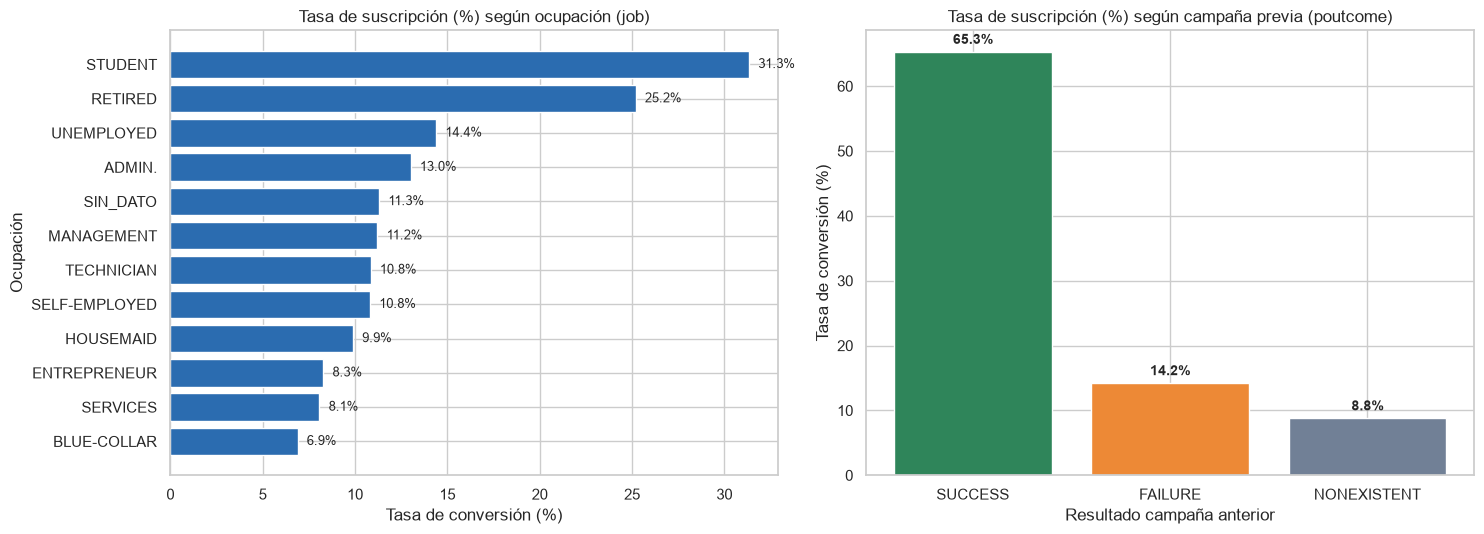

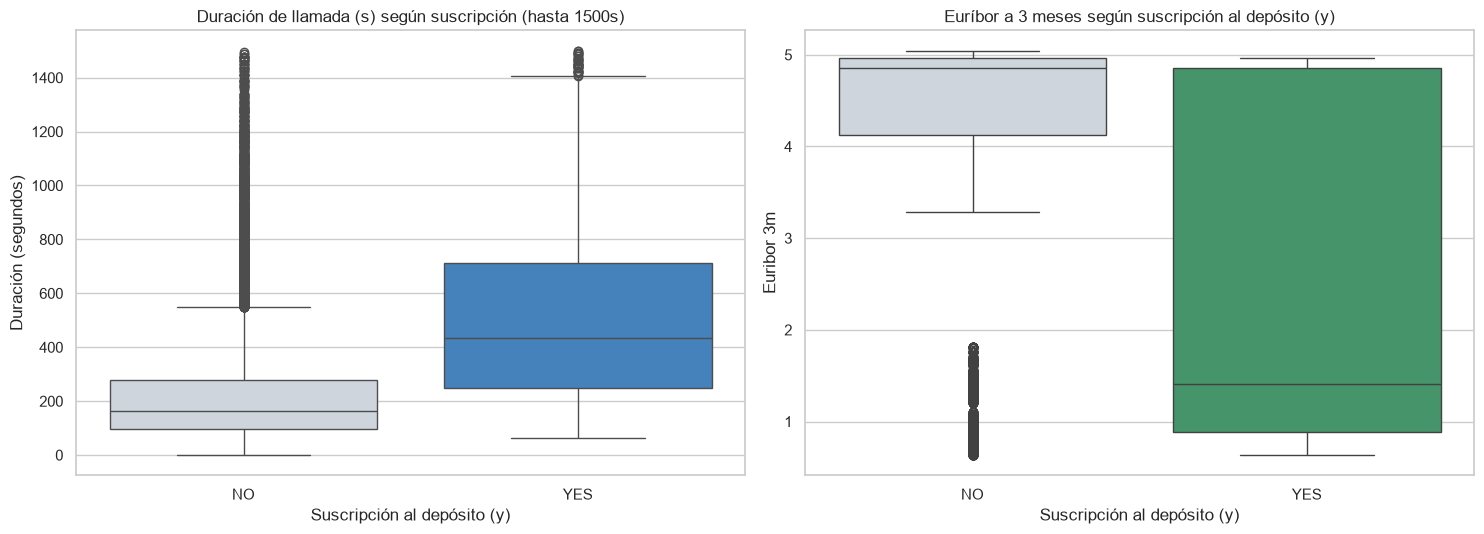

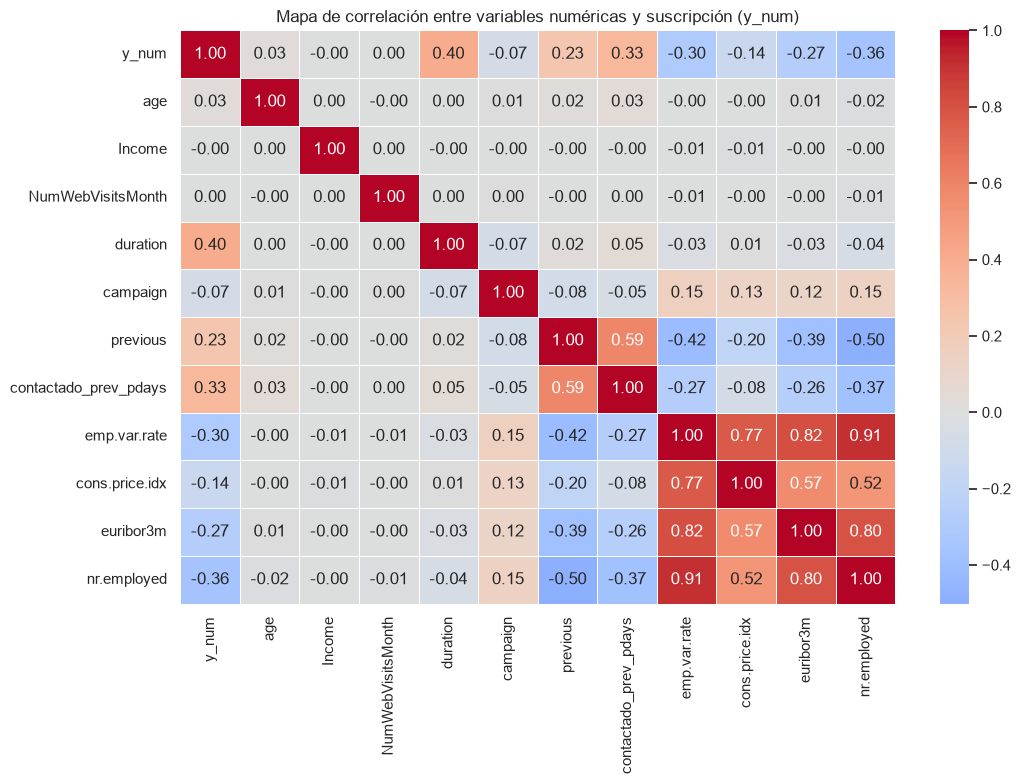

In [32]:
sns.set_theme(style="whitegrid")
df_viz = df_clientes_datos_banco_clean.copy()

# 1. Tasa de suscripción (%) por ocupación (job) y campaña previa (poutcome)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

job_conv = (df_viz.groupby("job")["y_num"].mean() * 100).sort_values(
    ascending=True
)
axes[0].barh(job_conv.index, job_conv.values, color="#2b6cb0")
axes[0].set_title("Tasa de suscripción (%) según ocupación (job)")
axes[0].set_xlabel("Tasa de conversión (%)")
axes[0].set_ylabel("Ocupación")
for idx, val in enumerate(job_conv.values):
  axes[0].text(val + 0.5, idx, f"{val:.1f}%", va="center", fontsize=9)

pout_conv = (df_viz.groupby("poutcome")["y_num"].mean() * 100).sort_values(
    ascending=False
)
axes[1].bar(
    pout_conv.index,
    pout_conv.values,
    color=["#2f855a", "#ed8936", "#718096"],
)
axes[1].set_title("Tasa de suscripción (%) según campaña previa (poutcome)")
axes[1].set_xlabel("Resultado campaña anterior")
axes[1].set_ylabel("Tasa de conversión (%)")
for idx, val in enumerate(pout_conv.values):
  axes[1].text(
      idx, val + 1.2, f"{val:.1f}%", ha="center", fontsize=10, fontweight="bold"
  )

plt.tight_layout()
plt.show()

# 2. Boxplots de duración de llamada (truncado a 1500s) y euribor3m según 'y'
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

df_dur_clip = df_viz[df_viz["duration"] <= 1500]
sns.boxplot(
    data=df_dur_clip,
    x="y",
    y="duration",
    hue="y",
    legend=False,
    ax=axes[0],
    palette={"NO": "#cbd5e0", "YES": "#3182ce"},
)
axes[0].set_title(
    "Duración de llamada (s) según suscripción (hasta 1500s)"
)
axes[0].set_xlabel("Suscripción al depósito (y)")
axes[0].set_ylabel("Duración (segundos)")

sns.boxplot(
    data=df_viz,
    x="y",
    y="euribor3m",
    hue="y",
    legend=False,
    ax=axes[1],
    palette={"NO": "#cbd5e0", "YES": "#38a169"},
)
axes[1].set_title("Euríbor a 3 meses según suscripción al depósito (y)")
axes[1].set_xlabel("Suscripción al depósito (y)")
axes[1].set_ylabel("Euribor 3m")

plt.tight_layout()
plt.show()

# 3. Mapa de calor (heatmap) de correlaciones numéricas clave
cols_corr = [
    "y_num",
    "age",
    "Income",
    "NumWebVisitsMonth",
    "duration",
    "campaign",
    "previous",
    "contactado_prev_pdays",
    "emp.var.rate",
    "cons.price.idx",
    "euribor3m",
    "nr.employed",
]
cols_corr_existentes = [c for c in cols_corr if c in df_viz.columns]
corr_matrix = df_viz[cols_corr_existentes].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5
)
plt.title("Mapa de correlación entre variables numéricas y suscripción (y_num)")
plt.tight_layout()
plt.show()

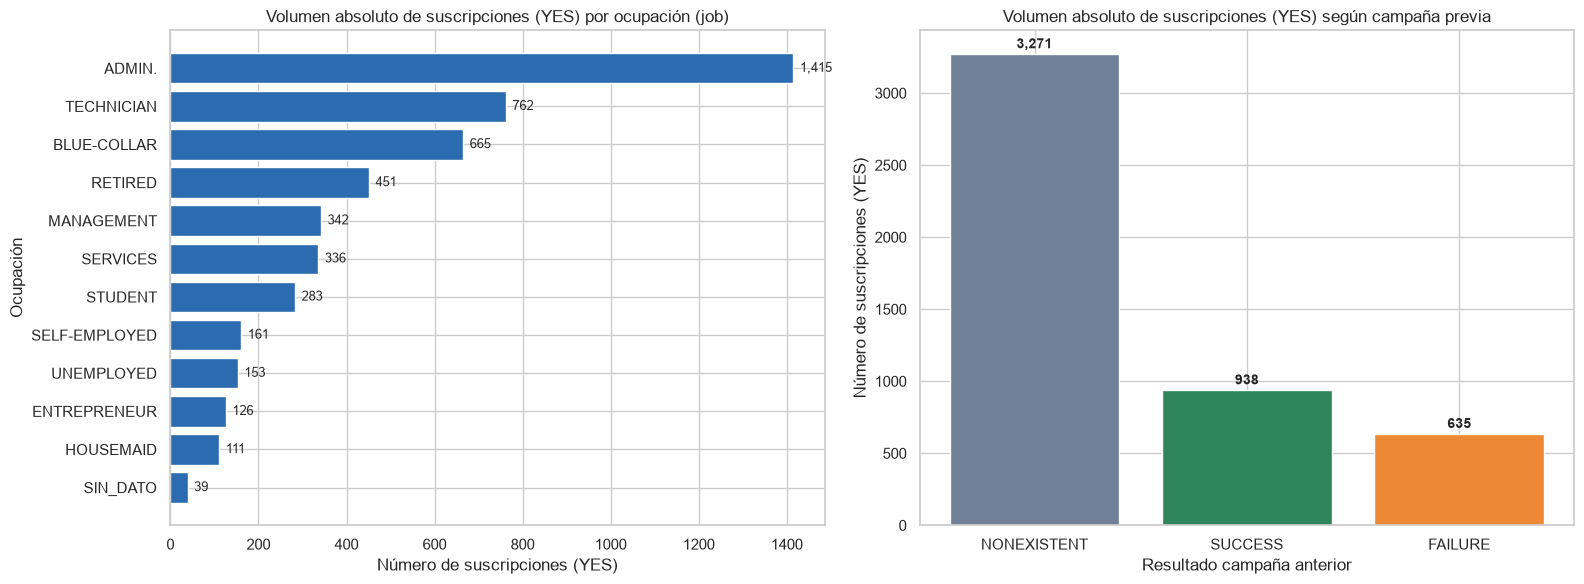

In [33]:
# ==========================================
# VOLUMEN ABSOLUTO DE SUSCRIPCIONES (YES)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Número absoluto de 'YES' por ocupación (job)
yes_por_job = (
    df_viz[df_viz["y"] == "YES"]
    .groupby("job")
    .size()
    .sort_values(ascending=True)
)
axes[0].barh(yes_por_job.index, yes_por_job.values, color="#2b6cb0")
axes[0].set_title(
    "Volumen absoluto de suscripciones (YES) por ocupación (job)"
)
axes[0].set_xlabel("Número de suscripciones (YES)")
axes[0].set_ylabel("Ocupación")
for idx, val in enumerate(yes_por_job.values):
  axes[0].text(val + 15, idx, f"{val:,}", va="center", fontsize=9)

# 2. Número absoluto de 'YES' por campaña previa (poutcome)
yes_por_pout = (
    df_viz[df_viz["y"] == "YES"]
    .groupby("poutcome")
    .size()
    .sort_values(ascending=False)
)
axes[1].bar(
    yes_por_pout.index,
    yes_por_pout.values,
    color=["#718096", "#2f855a", "#ed8936"],
)
axes[1].set_title(
    "Volumen absoluto de suscripciones (YES) según campaña previa"
)
axes[1].set_xlabel("Resultado campaña anterior")
axes[1].set_ylabel("Número de suscripciones (YES)")
for idx, val in enumerate(yes_por_pout.values):
  axes[1].text(
      idx, val + 40, f"{val:,}", ha="center", fontsize=10, fontweight="bold"
  )

plt.tight_layout()
plt.show()

Informe final de conclusiones
1.	Resumen ejecutivo y contexto de la campaña
2.	Calidad del dato, preparación y rigor estadístico
3.	Eficiencia vs. volumen: lectura porcentual y absoluta de la conversión
4.	Dinámica de contacto y duración de las llamadas
5.	Otras variables relevantes: perfil demográfico, ciclo de vida del cliente y macroeconomía
6.	Limitaciones del análisis y recomendaciones accionables
7.	Contratiempos y otras circunstancias
Borrador de informe de conclusiones
1. Resumen ejecutivo y contexto de la campaña
El análisis abarca 43.000 registros resultantes de cruzar los datos de clientes (customer-details.xlsx, con registros de 2012 a 2014) y la información de campañas de marketing telefónico y contexto macroeconómico (bank-additional.csv).
La variable objetivo (y) muestra una fuerte asimetría de clases: aproximadamente el 11,27 % de los contactos concluyen en suscripción del depósito a plazo (YES), frente a un 88,73 % que no contratan (NO). En consecuencia, una campaña de captación telefónica de este tipo no se evalúa solo por el porcentaje de acierto global, sino por cómo se reparte la conversión entre distintos segmentos y qué palancas explican las diferencias de respuesta.
2. Calidad del dato, preparación y rigor estadístico
La fase de limpieza y transformación resolvió problemas críticos que habrían distorsionado el análisis si se hubieran dejado tal cual:
•	Unión e integridad: Se consolidaron ambas fuentes mediante ID / id_, eliminando columnas auxiliares redundantes (Unnamed: 0_x, Unnamed: 0_y e id_) y verificando la ausencia de filas duplicadas exactas.
•	Tipado y formatos: Se convirtieron a numérico (float64) indicadores económicos almacenados como texto con coma decimal (cons.price.idx, cons.conf.idx, euribor3m, nr.employed) y se normalizaron las fechas (date desde formato textual en español y Dt_Customer a datetime64), además de estandarizar cadenas de texto y documentar valores nulos (SIN_DATO en categorías seleccionadas y mediana en variables numéricas continuas).
•	Variables derivadas: Se incorporaron y_num para facilitar el cálculo de tasas de conversión, contactado_prev_pdays para separar el código centinela 999 (sin contacto previo registrado en campaña) del resto de registros, y variables temporales (anio_contacto, mes_contacto).
•	Uso de medianas y métricas de forma: Variables como duration, campaign y previous presentan marcada asimetría positiva y curtosis elevada, lo que indica colas largas y valores extremos. Por ello, acompañar la media con la mediana (y revisar gráficos como boxplots acotados) resulta indispensable para describir el comportamiento típico sin que los extremos sesguen la lectura.
3. Eficiencia vs. volumen: lectura porcentual y absoluta de la conversión
Uno de los hallazgos principales del análisis es la diferencia entre tasa de conversión (%) y volumen absoluto de contrataciones (YES):
•	En términos porcentuales (eficiencia):
o	El historial de campañas anteriores (poutcome) marca una brecha muy clara: quienes tuvieron éxito previo (SUCCESS) alcanzan una tasa de conversión en torno al 65,32 %, frente al 14,23 % en FAILURE y al 8,82 % en NONEXISTENT. De forma coherente, contactado_prev_pdays == 1 presenta una conversión cercana al 64,04 % frente al 9,24 % de quienes no registran contacto previo (999).
o	Por ocupación (job), destacan en tasa porcentual los segmentos STUDENT (31,34 %) y RETIRED (25,20 %), seguidos por UNEMPLOYED (14,39 %). Estos grupos suelen tener dinámicas financieras o de disponibilidad distintas que favorecen una mayor propensión relativa al producto.
•	En términos absolutos (masa crítica):
o	Aunque STUDENT y RETIRED sobresalen en porcentaje, su peso numérico dentro del universo total es menor que el de ocupaciones amplias como ADMIN., BLUE-COLLAR o TECHNICIAN, y la gran mayoría de clientes parten de NONEXISTENT (pdays == 999).
o	Por tanto, el volumen total de suscripciones (YES) depende en gran medida de estos grupos mayoritarios: mejorar ligeramente la conversión en ADMIN., TECHNICIAN o BLUE-COLLAR—especialmente cuando existe un antecedente favorable o en bases amplias sin contacto previo— puede generar un impacto absoluto notable, siempre vigilando el tamaño muestral al realizar cruces múltiples.
4. Dinámica de contacto y duración de las llamadas
•	Duración (duration): Las operaciones con resultado YES presentan duraciones sustancialmente mayores que las NO (con una media cercana a 551,62 s frente a 220,43 s, y medianas de 449,0 s frente a 163,0 s). Sin embargo, desde una perspectiva analítica rigurosa, duration es una variable ex post (se conoce al finalizar la llamada): una llamada corta suele reflejar un rechazo temprano, mientras que una llamada larga acompaña a conversaciones donde hay interés y explicación de condiciones. El objetivo operativo no es forzar llamadas largas sin criterio, sino sostener conversaciones de calidad cuando el cliente muestra receptividad.
•	Frecuencia de contactos en la campaña (campaign): La tasa de conversión tiende a descender a medida que aumentan los intentos dentro de la misma campaña (pasando de 13,02 % en el primer contacto a 5,53 % cuando se alcanzan 6 o más contactos). Insistir repetidamente sobre un mismo cliente muestra rendimientos decrecientes y mayor riesgo de saturación.
•	Canal de contacto (contact): El contacto vía telefonía móvil (CELLULAR) muestra una tasa de conversión superior (14,74 %) frente a telefonía fija (TELEPHONE, 5,16 %), sugiriendo diferencias de accesibilidad o efectividad del canal.
5. Otras variables relevantes: perfil demográfico, ciclo de vida del cliente y macroeconomía
Más allá de los factores comentados en primer lugar, el dataset incorpora otras dimensiones que conviene integrar en la lectura global:
•	Entorno macroeconómico (euribor3m, emp.var.rate, cons.price.idx, cons.conf.idx, nr.employed):
o	Los datos muestran que las suscripciones (YES) se asocian con niveles de euribor3m más bajos en promedio y, sobre todo, en mediana (1,40 en YES frente a 4,86 en NO), así como correlaciones lineales negativas moderadas de y_num con variables como nr.employed y emp.var.rate.
o	En términos económicos, el contexto de tipos de interés condicionan el atractivo relativo de un depósito a plazo frente a otras alternativas o frente a las necesidades de liquidez de los hogares.
•	Variables demográficas y del hogar (age, marital, education, Income, Kidhome, Teenhome):
o	age presenta una ligera asimetría positiva y mayor presencia de perfiles retirados o jóvenes en los extremos con tasas altas, mientras que Income muestra una distribución amplia y bastante simétrica en su rango general, con diferencias moderadas entre YES y NO.
o	Kidhome y Teenhome reflejan la estructura familiar del hogar, un factor que puede influir en la capacidad de inmovilizar ahorro a plazo o en la disponibilidad para atender llamadas.
•	Relación previa y actividad digital (Dt_Customer, anio_registro_hoja, NumWebVisitsMonth, default, housing, loan):
o	Dt_Customer y anio_registro_hoja permiten situar la antigüedad del alta del cliente en el banco (2012–2014) frente a la fecha de contacto de la campaña (date).
o	NumWebVisitsMonth aporta una señal de interacción digital mensual del cliente, mientras que default, housing y loan describen su situación crediticia/patrimonial básica (con un volumen relevante de registros sin dato en default, lo que aconseja tratar esa categoría con cautela).
6. Limitaciones del análisis y recomendaciones accionables
•	Limitaciones: El análisis es de carácter descriptivo y exploratorio (no establece causalidad pura ni incluye modelado predictivo multivariante); además, variables como duration no están disponibles antes de realizar la llamada y varias columnas presentan valores ausentes o categorías SIN_DATO / NONEXISTENT que deben considerarse al interpretar resultados.
•	Recomendaciones:
1.	Priorizar leads con historial favorable (poutcome == 'SUCCESS' / contactado_prev_pdays == 1) por su altísima eficiencia relativa.
2.	Combinar foco de eficiencia y escala: Mantener campañas específicas para segmentos con alta tasa porcentual (STUDENT, RETIRED) y, al mismo tiempo, optimizar guiones y segmentación en los grandes grupos de volumen (ADMIN., TECHNICIAN, BLUE-COLLAR y NONEXISTENT) para maximizar el número total de altas.
3.	Limitar el número de reintentos (campaign) y priorizar CELLULAR, evitando insistir en exceso cuando no hay respuesta favorable.
4.	Contextualizar las metas comerciales según el entorno macroeconómico (euribor3m y variables de empleo), ajustando expectativas y argumentario cuando cambian las condiciones de tipos y ahorro.

7. Contratiempos y otras circunstancias
•	Al cargar el Excel “customer-details.xlsx” nos encontramos con la circunstancia de que tiene varias paginas. Para no caer en la trampa de unificarlo en Excel recurrimos a la IA para dar una solución.
•	Tuve que recurrir a IA intensamente en primer lugar para intentar conocer los significados de las columnas y sus implicaciones.
•	Posteriormente las relaciones entre estas columnas eran ligeramente más evidentes pero sus implicaciones en como se afectan entre ellas no tanto.
•	Aunque los pasos de limpieza y transformación estaban claros el uso de IA ha sido fácil para expresar el código de una manera limpia y estructurada.
•	No obstante en la fase de Analisis Descriptivo el criterio sobre las preguntas de negocio y visualización tanto en términos porcentuales como absolutos ha prevalecido.
